# MicroDuck HelloWorld：用 Python 控制 MuJoCo 中的小鸭子

下载行走策略，在同一个物理场景中依次执行 **站稳 → 前进 → 左转 → 停止**。
本教程不需要训练模型、GPU 或开发板。策略在本机 ONNX Runtime 上运行，MuJoCo 计算运动与接触。

闭环是：**Python 速度命令 → 实时机器人观测 → 策略推理 → 14 个关节目标 → MuJoCo 物理更新 → 下一步观测**。
下方直接展示控制循环和 `data.ctrl` 下发；重新运行会生成新视频。
原有 8 天学习计划保持不变，这是一份开始任务学习前的入门向导。

## 1. 准备最小环境

克隆完整仓库，保留机器人 XML 和网格文件，然后打开这本 Notebook，从上到下运行。
推荐 Python 3.11 或 3.12。依赖见 `02-可运行代码/hello-world/requirements.txt`，
下方只在缺少依赖时安装；模型在下一节自动下载。环境启动步骤见[HelloWorld 说明](../02-可运行代码/hello-world/README.md)。
Ubuntu 无桌面时使用 EGL；Windows/macOS 使用 MuJoCo 的默认渲染后端。

In [1]:
import os
import sys
import subprocess
from pathlib import Path
from importlib.util import find_spec
from importlib.metadata import version
if sys.platform.startswith("linux"):
    os.environ.setdefault("MUJOCO_GL", "egl")

def locate_topic():
    configured = os.getenv("MICRODUCK_TOPIC_ROOT")
    if configured:
        return Path(configured).expanduser().resolve()
    for base in (Path.cwd(), *Path.cwd().parents):
        for candidate in (base, base / "16-专题组队学习/05-MicroDuck运动策略与任务开发专题"):
            if (candidate / "02-可运行代码/hello-world").is_dir():
                return candidate
    raise FileNotFoundError("请从仓库或本专题目录启动 Jupyter。")

TOPIC = locate_topic()
CODE = TOPIC / "02-可运行代码/hello-world"
PLAYGROUND = TOPIC / "02-可运行代码/microduck-playground-stilts"
missing = [name for name in ("mujoco", "onnxruntime", "numpy", "matplotlib", "imageio", "imageio_ffmpeg")
           if find_spec(name) is None]
if missing:
    subprocess.run([sys.executable, "-m", "pip", "install", "-r", str(CODE / "requirements.txt")], check=True)
sys.path.insert(0, str(CODE))
import numpy as np
import mujoco
import imageio.v2 as imageio
import json
from IPython.display import display, Image, Video, Markdown
from walking_sim import WalkingSimulation, prepare_policy, sha256, save_gif, save_report
OUTPUT = TOPIC / "03-Notebook/outputs/control_helloworld"
OUTPUT.mkdir(parents=True, exist_ok=True)
print({name: version(name) for name in ("mujoco", "onnxruntime", "numpy")})
print("本次流程：站稳、前进、左转、停止；使用本机策略推理。")

{'mujoco': '3.16.0', 'onnxruntime': '1.31.0', 'numpy': '2.5.4'}
本次流程：站稳、前进、左转、停止；使用本机策略推理。


## 2. 自动获取行走模型

使用 [MicroDuck 模拟器的行走策略](https://huggingface.co/spaces/pollen-robotics/microduck-simulator/tree/ad9d41a763f30dc770817c33d92dcfec0205db1e/app/public/policies)。
固定模型版本与 SHA-256；文件约 0.8 MB，缓存到用户目录，后续复用。
这个模型接收 `obs[1,61]`，输出 `action[1,14]`。61 维中的 `[48:51]` 是速度命令 `[vx, vy, yaw_rate]`。
若下载受限，可在运行前设置 `MICRODUCK_DOWNLOAD_PROXY`。

In [2]:
POLICY = prepare_policy()
print("行走模型已就绪，SHA-256:", sha256(POLICY))
print("速度单位：vx/vy 为 m/s；yaw_rate 为 rad/s，正值左转。")

行走模型已就绪，SHA-256: e36332d383997d51401897734cd3e79cf5038406feddb18b4d57ecfb141daa6c
速度单位：vx/vy 为 m/s；yaw_rate 为 rad/s，正值左转。


## 3. 创建 MuJoCo 物理场景

加载仓库中的 `scene.xml` 与机器人资产，读取真实传感器、关节位置和关节速度。
初始化一次站立姿态后，各命令单元继续使用同一个 `sim.data`，不会在前进、转向之间重置位置。
仿真每秒更新 200 次，策略每秒更新 50 次；这里没有运行训练任务。

模型输入: [('obs', [1, 61])]
模型输出: [('actions', [1, 14])]
MuJoCo 执行器数量: 14 ；控制周期: 0.02 s
初始身体状态: {'time_s': 0.0, 'x_m': 0.0, 'y_m': 0.0, 'height_m': 0.125, 'yaw_rad': 0.0, 'vx_m_s': 0.0, 'upright_cos': 1.0}


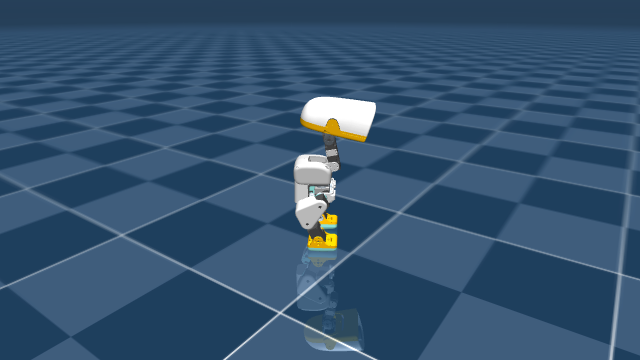

In [3]:
sim = WalkingSimulation(PLAYGROUND, POLICY)
print("模型输入:", [(x.name, x.shape) for x in sim.session.get_inputs()])
print("模型输出:", [(x.name, x.shape) for x in sim.session.get_outputs()])
print("MuJoCo 执行器数量:", sim.model.nu, "；控制周期:", sim.control_dt, "s")
print("初始身体状态:", sim.state())
preview = display(Image(data=imageio.imwrite("<bytes>", sim.render(), format="png"), width=640), display_id=True)

## 4. 先亲手执行一个完整控制步

`sim.observation()` 读取此刻的仿真状态，`session.run()` 计算关节动作。
`sim.apply_action()` 把 `默认关节角 + action_scale × action` 写入 `sim.data.ctrl`。
接着真正调用 `mujoco.mj_step()`，物理状态更新后才读取下一条观测。
命令是期望运动速度；策略输出是关节目标偏移，两者不能直接互换。

In [4]:
sim.stop()
observation = sim.observation()
action = sim.session.run([sim.output_name], {sim.input_name: observation})[0]
target = sim.apply_action(action)
for _ in range(4):
    mujoco.mj_step(sim.model, sim.data)
next_observation = sim.observation()
print("传给策略的速度命令:", observation[0, 48:51])
print("观测 -> 动作 -> 执行器目标:", observation.shape, action.shape, sim.data.ctrl.shape)
print("已下发前 5 个关节目标(rad):", np.round(target[:5], 4))
print("MuJoCo 已推进到:", round(sim.data.time, 3), "s")
print("更新后的观测变化量:", float(np.max(np.abs(next_observation - observation))))

传给策略的速度命令: [0. 0. 0.]
观测 -> 动作 -> 执行器目标: (1, 61) (1, 14) (14,)
已下发前 5 个关节目标(rad): [-0.0186 -0.1384 -0.4615  0.0216  0.3203]
MuJoCo 已推进到: 0.02 s
更新后的观测变化量: 0.6123867034912109


## 5. 持续运行控制循环

下面的循环每一步读取新观测、重新推理、下发关节目标，再推进物理仿真。
`realtime=True` 时按墙钟时间以 50 Hz 运行；默认尽快计算，视频仍按 50 FPS 播放。
Notebook 等待下一条命令时，仿真时间暂停；下一单元从当前姿态继续。
画面来自当前仿真，MP4 在这个循环中逐帧生成。

In [5]:
import time
VIDEO_PATH = OUTPUT / "microduck_forward_turn_stop.mp4"
writer = imageio.get_writer(VIDEO_PATH, fps=50, codec="libx264", macro_block_size=None,
                           ffmpeg_params=["-movflags", "+faststart"])
trace = []

def run_for_seconds(seconds, phase, realtime=False):
    steps = round(seconds / sim.control_dt)
    if steps <= 0:
        raise ValueError("运行时长必须为正数。")
    started = time.monotonic()
    try:
        for step in range(steps):
            # Read the current state and command, then infer a fresh action.
            obs = sim.observation()
            actions = sim.session.run([sim.output_name], {sim.input_name: obs})[0]
            assert actions.shape == (1, 14) and np.isfinite(actions).all()
            # These are position targets for the MuJoCo actuators.
            sim.data.ctrl[:] = sim.default_pose + sim.action_scale * actions[0]
            sim.last_action[:] = actions[0]
            for _ in range(4):
                mujoco.mj_step(sim.model, sim.data)
            assert np.isfinite(sim.data.qpos).all()
            state = sim.state()
            if state["height_m"] < 0.065 or state["upright_cos"] < 0.7:
                raise RuntimeError("机器人失稳；停止本次演示并检查模型与场景。")
            trace.append({**state, "phase": phase, "command": obs[0,48:51].tolist(),
                          "action": actions[0].tolist(), "ctrl_rad": sim.data.ctrl.tolist()})
            frame = sim.render()
            writer.append_data(frame)
            if step % 25 == 0:
                preview.update(Image(data=imageio.imwrite("<bytes>", frame, format="png"), width=640))
            if realtime:
                remaining = started + (step + 1) * sim.control_dt - time.monotonic()
                if remaining > 0:
                    time.sleep(remaining)
    except BaseException:
        writer.close()
        sim.close()
        raise
    print(phase, "已执行", steps, "个闭环控制步；状态:", sim.state())

print("控制循环已就绪：观测读取 -> 策略推理 -> data.ctrl -> mj_step。")

控制循环已就绪：观测读取 -> 策略推理 -> data.ctrl -> mj_step。


## 6. 先站稳

将速度命令设为零，持续运行 1 秒。关节仍由策略控制，而不是将 14 个关节目标全部清零。

In [6]:
sim.stop()
run_for_seconds(1.0, "settle")

settle 已执行 50 个闭环控制步；状态: {'time_s': 1.0200000000000002, 'x_m': 0.0017299538311630928, 'y_m': 7.73148444035204e-05, 'height_m': 0.11655530332642905, 'yaw_rad': -0.0023874333985902533, 'vx_m_s': 0.0008737485019463521, 'upright_cos': 0.9999784067405579}


## 7. 下发前进命令

`sim.forward(0.30)` 表示期望向机器人前方以 0.30 m/s 行走。
修改这一行的速度即可做自己的实验。先使用默认值，完成整条流程。

In [7]:
sim.forward(speed=0.30)
print("已下发前进命令:", sim.command[:3])
run_for_seconds(4.0, "forward")

已下发前进命令: [0.3 0.  0. ]


forward 已执行 200 个闭环控制步；状态: {'time_s': 5.019999999999915, 'x_m': 0.4827321806704948, 'y_m': -0.012835695084774416, 'height_m': 0.11591476343142794, 'yaw_rad': -0.10439254266035512, 'vx_m_s': 0.13261415925069525, 'upright_cos': 0.9996297339055005}


## 8. 下发转向命令

将前进速度设为零，期望左转角速度为 0.50 rad/s。
负值表示右转。这里改变策略输入中的命令，不直接修改机器人的朝向。

In [8]:
sim.turn(yaw_rate=0.50)
print("已下发左转命令:", sim.command[:3])
run_for_seconds(3.0, "turn_left")

已下发左转命令: [0.  0.  0.5]


turn_left 已执行 150 个闭环控制步；状态: {'time_s': 8.019999999999854, 'x_m': 0.5268091660429072, 'y_m': 0.01655188427745513, 'height_m': 0.12069580285854516, 'yaw_rad': 0.7106934245634797, 'vx_m_s': 0.03245451983874416, 'upright_cos': 0.9981046866485073}


## 9. 下发停止命令

`sim.stop()` 将 `vx/vy/yaw_rate` 设为零，策略继续推理并控制站稳。
停止命令与关闭电机、停止物理仿真是不同操作；鸭子需要时间减速。

In [9]:
sim.stop()
print("已下发停止命令:", sim.command[:3])
run_for_seconds(3.0, "stop")

已下发停止命令: [0. 0. 0.]


stop 已执行 150 个闭环控制步；状态: {'time_s': 11.020000000000323, 'x_m': 0.5166582556259394, 'y_m': 0.019979385577528277, 'height_m': 0.1165540635352311, 'yaw_rad': 0.5685062751687857, 'vx_m_s': 0.0004923288336584455, 'upright_cos': 0.9999791220002284}


## 10. 检查实际运动，而不只检查模型形状

记录前进位移、转向角度、停止后的平均速度和站立状态。
每个控制步的命令、动作与实际关节目标也保存在 JSON 中，方便检查策略怎样影响仿真。

In [10]:
writer.close()
report = save_report(OUTPUT / "control_report.json", trace, POLICY)
print("累计闭环步数:", report["steps"])
for phase, result in report["phases"].items():
    print(phase, json.dumps(result, ensure_ascii=False))
assert report["phases"]["forward"]["dx_m"] > 0.3
assert report["phases"]["turn_left"]["yaw_change_rad"] > 0.3
assert report["phases"]["stop"]["last_second_mean_abs_vx_m_s"] < 0.08
assert report["phases"]["stop"]["command"] == [0.0, 0.0, 0.0]
print("闭环检查通过：前进、左转、停止均产生了对应的实际运动。")

累计闭环步数: 550
settle {"steps": 50, "command": [0.0, 0.0, 0.0], "dx_m": 0.0020654198544867246, "dy_m": 0.000116363213390694, "yaw_change_rad": -0.0029032749827194943, "last_second_mean_abs_vx_m_s": 0.00402921409812987}
forward {"steps": 200, "command": [0.30000001192092896, 0.0, 0.0], "dx_m": 0.4806807497213359, "dy_m": -0.012936814365498355, "yaw_change_rad": -0.10204371293876198, "last_second_mean_abs_vx_m_s": 0.13443885041949652}
turn_left {"steps": 150, "command": [0.0, 0.0, 0.5], "dx_m": 0.041821069929975196, "dy_m": 0.03217880183194807, "yaw_change_rad": 0.8012183508923215, "last_second_mean_abs_vx_m_s": 0.02012217661272667}
stop {"steps": 150, "command": [0.0, 0.0, 0.0], "dx_m": -0.008060788239303784, "dy_m": 0.0005003939283229029, "yaw_change_rad": -0.1398358065701253, "last_second_mean_abs_vx_m_s": 0.0005808252936901508}
闭环检查通过：前进、左转、停止均产生了对应的实际运动。


## 11. 对照命令与身体响应

期望速度变化后，实际速度通过关节动作和物理接触逐渐改变。
曲线与上面的完整控制过程使用同一份记录。

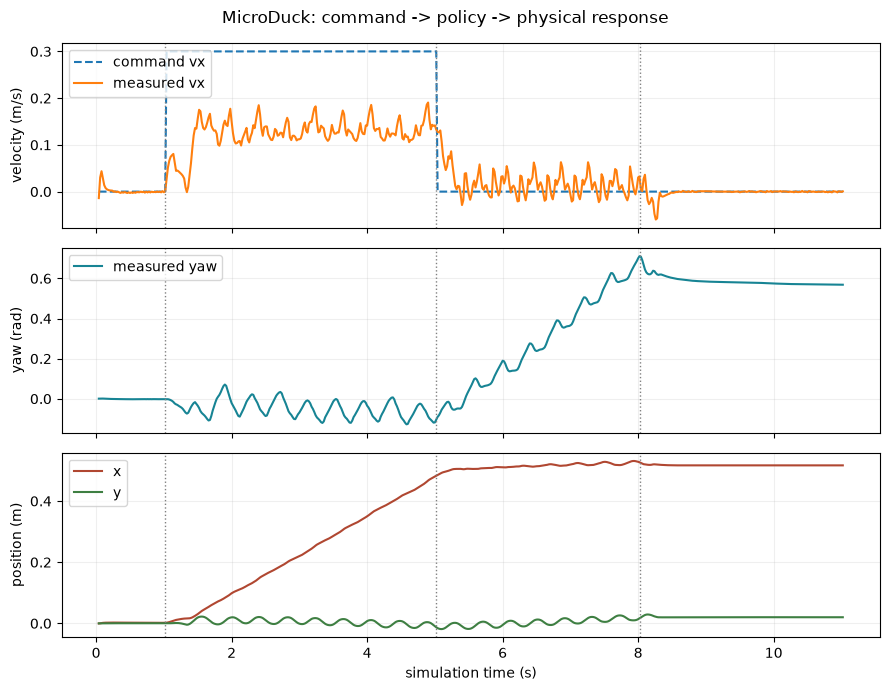

虚线边界依次对应前进、左转和停止命令。


In [11]:
import matplotlib.pyplot as plt
t = np.asarray([row["time_s"] for row in trace])
fig, axes = plt.subplots(3, 1, figsize=(9, 7), sharex=True)
axes[0].plot(t, [row["command"][0] for row in trace], label="command vx", linestyle="--")
axes[0].plot(t, [row["vx_m_s"] for row in trace], label="measured vx")
axes[0].set_ylabel("velocity (m/s)")
axes[1].plot(t, np.unwrap([row["yaw_rad"] for row in trace]), label="measured yaw", color="#178494")
axes[1].set_ylabel("yaw (rad)")
axes[2].plot(t, [row["x_m"] for row in trace], label="x", color="#b04731")
axes[2].plot(t, [row["y_m"] for row in trace], label="y", color="#3e7f42")
axes[2].set_ylabel("position (m)")
axes[2].set_xlabel("simulation time (s)")
for ax in axes:
    ax.grid(alpha=0.2)
    ax.legend(loc="upper left")
    for boundary in (1.02, 5.02, 8.02):
        ax.axvline(boundary, color="gray", linestyle=":", linewidth=1)
fig.suptitle("MicroDuck: command -> policy -> physical response")
plt.tight_layout()
plt.show()
print("虚线边界依次对应前进、左转和停止命令。")

## 12. 播放本次完整视频

视频在上面的策略闭环中生成。工作站保存完整 MP4，仓库保存 GIF 供直接阅读。
重跑会覆盖本实验的最新视频。

In [12]:
ASSETS = TOPIC / "01-任务资料/07-RDK端侧与网页部署/assets/hello_world"
ASSETS.mkdir(parents=True, exist_ok=True)
GIF_PATH = save_gif(VIDEO_PATH, ASSETS / "forward_turn_stop.gif")
display(Video("outputs/control_helloworld/microduck_forward_turn_stop.mp4", embed=False, width=640))
print("本次视频已保存；包含站稳、前进、左转和停止的完整过程。")
sim.close()

本次视频已保存；包含站稳、前进、左转和停止的完整过程。


## 接下来怎样学习任务与实机

可以重新运行整本 Notebook，修改 `sim.set_command(vx=0.30, yaw_rate=0.30)`，
比较直走、弧线和原地转向。需要按真实时间演示时，给 `run_for_seconds()` 加上 `realtime=True`。

完成 HelloWorld 后再进入篮球、高跷、爬梯和导航等任务：它们沿用这条闭环，但使用自己的场景、观测和策略。
`data.ctrl` 在这里连接 MuJoCo 的位置执行器。实机接入使用机器人 SDK 读取 IMU/关节状态，
再按同一关节顺序向舵机发送目标位置；频率、零位、限位和急停先按硬件接口校验。
RDK BPU 是这条流程中策略推理部分的另一种运行方式，见[第 7 本 Notebook](./07_RDK网页与多策略_BPU验收.ipynb)。